# SymPhase tutorial 6 — non-collinear ferro- and antiferromagnets

**Symmetry.** For non-collinear orders the spin part $U$ of every spin-group element $[U\|g]$ is found by an orthogonal
Procrustes fit ($\mathbf m_{g(i)}=U\mathbf m_i$); the spin-only group is $\{E,\,C_2(\hat{\mathbf n})\mathcal T\}$ for coplanar and
trivial for non-coplanar orders. SymPhase classifies compensated orders as non-collinear antiferromagnets and uncompensated
ones (canted, weak ferromagnets, ferrimagnets) as non-collinear ferro/ferrimagnets, and finds the spin-splitting form $\mathbf s(\mathbf k)$
(odd p-/f-wave forms are possible).

**Magnons.** General linear spin-wave theory in local frames (S. Toth and B. Lake, J. Phys.: Condens. Matter **27**, 166002 (2015)):
each spin direction $\mathbf v_i$ gets $\mathbf u_i=\hat{\mathbf x}_i+i\hat{\mathbf y}_i$, and for $H=\sum\mathbf S_i^{T}J_{ij}\mathbf S_j+\sum\mathbf S_i^{T}A_i\mathbf S_i$
(Heisenberg, DMI $\mathbf D\cdot(\mathbf S_i\times\mathbf S_j)$ or full tensors)
$$A_{ij}(\mathbf k)\ni\tfrac{\sqrt{S_iS_j}}{2}\,\mathbf u_i^{T}J_{ij}\bar{\mathbf u}_j\,e^{i\mathbf k\cdot\mathbf d},\quad
B_{ij}(\mathbf k)\ni\tfrac{\sqrt{S_iS_j}}{2}\,\mathbf u_i^{T}J_{ij}\mathbf u_j\,e^{i\mathbf k\cdot\mathbf d},\quad
A_{ii}\ni-S_j\,\mathbf v_i^{T}J_{ij}\mathbf v_j .$$
Every mode carries a magnon spin vector $\Delta\mathbf S_n=-\sum_i\mathbf v_i\,(|T_{in}|^2+|T_{i+N,n}|^2)$; `--relax` minimises the classical energy first.

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

## 1. Symmetry of the non-collinear examples

In [2]:
from symphase import analyze_tensors
for c in ["Triangular_120AFM_INCAR", "CantedChain_DMI_INCAR", "Mn3Sn_allin"]:
    sg = analyze_tensors(f"{EX}/vasp/{c}", tensors="charge,spin")["spin_group"]
    print(f"{c:<24s} {sg['magnet_class']:<55s} {sg['spin_splitting']:<12s} {(sg['s_k'] or [''])[0]}")

Triangular_120AFM_INCAR  non-collinear antiferromagnet (coplanar)                f-wave       s_z = kx·ky² - 1/3·kx³
CantedChain_DMI_INCAR    non-collinear ferro/ferrimagnet (coplanar, net |m| = 0.780 muB) s-wave (Zeeman-like, uncompensated) s_x = 1


Mn3Sn_allin              non-collinear antiferromagnet (coplanar)                no non-relativistic spin splitting (spin-degenerate bands) 


## 2. Sanity check: a ferromagnet along [111] is identical to one along z

The local frames make the spectrum independent of the global spin direction; the magnon spin points along −[111].

In [3]:
import numpy as np, spglib, math
from symphase.magnons import analyse, plot_bands, read_exchange_file
lat, fr = np.eye(3) * 3.0, np.zeros((1, 3))
ds = spglib.get_symmetry_dataset((lat, fr, [0]))
rz = analyse(lat, fr, [0], ["Fe"], np.array([[0, 0, 2.]]), ds.rotations, ds.translations, J=[-1.0], rmax=3.1, n_per=20, nmap=3)
rd = analyse(lat, fr, [0], ["Fe"], np.array([[1, 1, 1.]]) * 2 / np.sqrt(3), ds.rotations, ds.translations,
             J=[-1.0], rmax=3.1, n_per=20, nmap=3)
print("max |ω_[111] − ω_z| =", np.abs(rz["omega"] - rd["omega"]).max(), " magnon spin:", np.round(rd["magnon_spin"][10, 0], 3))

max |ω_[111] − ω_z| = 2.6645352591003757e-15  magnon spin: [-0.577 -0.577 -0.577]


## 3. Triangular-lattice 120° antiferromagnet (coplanar)

Three sublattices in a $\sqrt3\times\sqrt3$ cell (POSCAR + INCAR only). Compare with the analytic result
$\omega(\mathbf k)=3JS\sqrt{(1-\gamma_{\mathbf k})(1+2\gamma_{\mathbf k})}$ folded with $\mathbf k\pm\mathbf K$:

max error: 0.00016431676095816613 meV;  Goldstone modes at Γ: 3


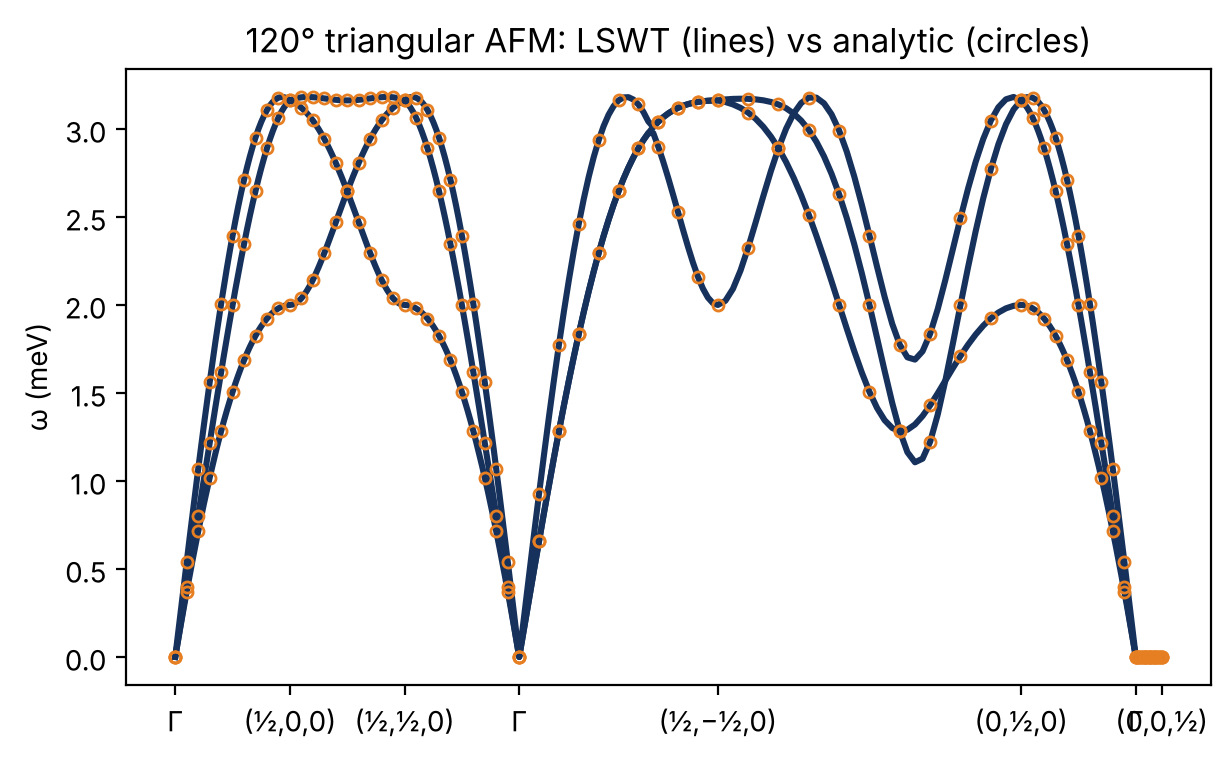

In [4]:
from symphase.tensors import read_poscar, read_incar
import matplotlib.pyplot as plt
d = f"{EX}/vasp/Triangular_120AFM_INCAR"
p = read_poscar(f"{d}/POSCAR"); mags = np.array(read_incar(f"{d}/INCAR")["magmom"]).reshape(-1, 3)
ds = spglib.get_symmetry_dataset((p["lattice"], p["frac"], [0, 0, 0]))
r = analyse(p["lattice"], p["frac"], [0, 0, 0], ["Cr"] * 3, mags, ds.rotations, ds.translations,
            J=[1.0], spin=1.0, rmax=3.1, n_per=40, nmap=3)
a = 3.0; a1, a2 = np.array([a, 0, 0]), np.array([a / 2, a * np.sqrt(3) / 2, 0]); K = np.array([4 * np.pi / (3 * a), 0, 0])
w = lambda k: 3 * np.sqrt(max((1 - (g := (np.cos(k @ a1) + np.cos(k @ a2) + np.cos(k @ (a2 - a1))) / 3)) * (1 + 2 * g), 0))
ana = np.array([np.sort([w(q), w(q + K), w(q - K)]) for q in r["q"]])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(r["x"], r["omega"], color="#16325c", lw=2.2)
ax.plot(r["x"][::4], ana[::4], "o", color="#e67e22", ms=4, mfc="none")
ax.set_xticks([t for t, _ in r["ticks"]]); ax.set_xticklabels([l for _, l in r["ticks"]]); ax.set_ylabel("ω (meV)")
ax.set_title("120° triangular AFM: LSWT (lines) vs analytic (circles)")
print("max error:", np.abs(np.sort(r["omega"], axis=1) - ana).max(), "meV;  Goldstone modes at Γ:", r["n_goldstone"])

## 4. Canted antiferromagnet (weak ferromagnet) from staggered DMI

Exchange file `J_DM.dat` (one line per bond: `i j n1 n2 n3 J Dx Dy Dz`). Starting from a collinear guess, `relax=True`
finds the canted ground state, tilted by $\varphi=\arctan(D/J)$ from antiparallel:

# i j n1 n2 n3   J    Dx   Dy   Dz      (meV)   H = S_i.J.S_j + D.(S_i x S_j)
1 2 0 0 0   1.0  0.0  0.2  0.0
2 1 1 0 0   1.0  0.0 -0.2  0.0



angle between spins: 168.69 °   expected 168.69
net moment: [-0.393  0.     0.029] muB/cell;  stable LSWT: True


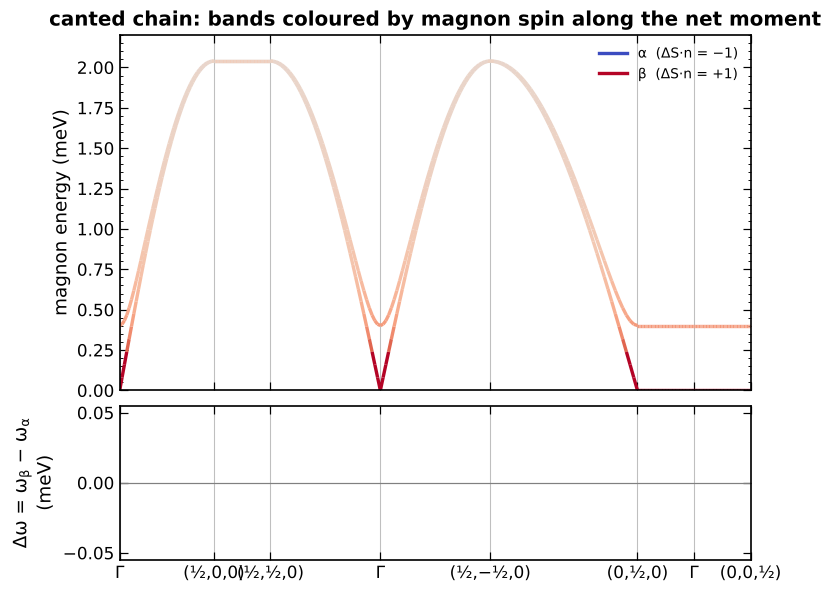

In [5]:
d = f"{EX}/vasp/CantedChain_DMI_INCAR"
print(open(f"{d}/J_DM.dat").read())
p = read_poscar(f"{d}/POSCAR"); ds = spglib.get_symmetry_dataset((p["lattice"], p["frac"], [0, 0]))
r = analyse(p["lattice"], p["frac"], [0, 0], ["Fe", "Fe"], np.array([[0.3, 0, 2.0], [0, 0, -2.0]]), ds.rotations,
            ds.translations, exchange=read_exchange_file(f"{d}/J_DM.dat"), spin=1.0, rmax=3.1, relax=True, n_per=40, nmap=3)
e = np.array(r["directions"])
print("angle between spins:", round(math.degrees(math.acos(e[0] @ e[1])), 3), "°   expected", round(180 - math.degrees(math.atan(0.2)), 3))
print("net moment:", np.round(r["net_moment"], 3), "muB/cell;  stable LSWT:", not r["unstable"])
fig = plot_bands(r, title="canted chain: bands coloured by magnon spin along the net moment")

## 5. Command line

```bash
cd examples/vasp/Triangular_120AFM_INCAR && symphase magnons --J 1.0 --rmax 3.1
cd examples/vasp/CantedChain_DMI_INCAR   && symphase magnons --exchange J_DM.dat --relax --rmax 3.1
symphase tensors --analysis spin        # spin group, magnet class and s(k) of any non-collinear order
```
Non-reciprocity $\omega(\mathbf q)\neq\omega(-\mathbf q)$ (e.g. from uniform DMI) is reported as `nonreciprocity`.
Continue with **09_quiz_spin_groups_magnons_finiteT.ipynb**.